# Hourly bike rental demand: end-to-end notebook

Group notebook for the MLOps course, built to be taken apart ("destroyed") together.

**Use case:** predict total bicycle rentals (`cnt`) for the next hour, so an Operations Manager can plan bicycle distribution.
**Data:** UCI Bike Sharing Dataset, `hour.csv` (Capital Bikeshare, 2011 to 2012). Scenario is hypothetical.
**Business case:** see the project README. Thresholds in the config cell come from it and are fixed before any results.

| Section | What happens |
| --- | --- |
| 0 | Config: every knob in one cell |
| 1 | Load and validate the data contract |
| 2 | Complete the hourly calendar (missing hours) |
| 3 | Features (past demand + calendar only) and leakage tests |
| 4 | Chronological split |
| 5 | Baseline: historical average by weekday and hour |
| 6 | Model: gradient boosting trained with the 2:1 asymmetric loss |
| 7 | Evaluation on the untouched test period |
| 8 | Release gate: pass or fail |

## 0. Config
Change things here first when we destroy the notebook. Nothing below hard-codes these values.

In [1]:
from pathlib import Path

# --- data ---
DATA_PATH = Path("hour.csv")
EXPECTED_ROWS = 17_379            # confirmed from the file; UCI pages list a different figure
TARGET = "cnt"

# --- chronological split (decided before looking at results) ---
TRAIN_END = "2012-06-30 23:00"    # train: start of data to this hour
VAL_END   = "2012-09-30 23:00"    # validation: after TRAIN_END to this hour; test: everything after

# --- inputs available at prediction time ---
LAG_MIN = 2                       # latest completed hour assumed NOT yet available (assumption to validate)
USE_WEATHER = False               # same-hour weather is unknown when predicting; forecasts could be added later
CALENDAR_FEATURES = ["hr", "weekday", "mnth", "season", "holiday", "workingday"]
WEATHER_FEATURES = ["weathersit", "temp", "atemp", "hum", "windspeed"]

# --- metric and release rules (from the business case) ---
UNDER_WEIGHT = 2.0                # under-prediction costs 2x over-prediction (assumption to validate)
QUANTILE = UNDER_WEIGHT / (1 + UNDER_WEIGHT)   # 2/3: the loss that this weighting is minimised by
REQUIRED_IMPROVEMENT = 0.15       # model must be at least 15% better than the baseline (assumption to validate)
MAX_P95_LATENCY_S = 1.0           # prediction response time limit
MAX_COST_EUR = 0.01               # per prediction; NOT measurable in a notebook, see section 8

# --- model ---
SEED = 42
MAX_ITER = 1500
LEARNING_RATE = 0.05
MAX_LEAF_NODES = 31
MIN_SAMPLES_LEAF = 40

# columns that must never be used as inputs (they contain or reveal the target)
FORBIDDEN_FEATURES = {"cnt", "casual", "registered", "is_imputed", "instant", "dteday", "ts"}

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

np.random.seed(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# plain colours, white background, thin lines
C_ACTUAL, C_MODEL, C_BASE, C_INK, C_GRID = "#52514e", "#2a78d6", "#eb6834", "#0b0b0b", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": C_GRID,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "text.color": C_INK, "lines.linewidth": 1.6, "figure.dpi": 110,
})


def weighted_mae(y_true, y_pred, under_weight=UNDER_WEIGHT):
    """Mean of weight * |error|, weight = under_weight when prediction < actual, else 1.
    Unit: rentals per hour. Lower is better."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    w = np.where(y_pred < y_true, under_weight, 1.0)
    return float(np.mean(w * np.abs(y_true - y_pred)))


def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true, float) - np.asarray(y_pred, float))))


def under_share(y_true, y_pred):
    """Share of hours where the forecast was below actual demand (potential shortage)."""
    return float(np.mean(np.asarray(y_pred, float) < np.asarray(y_true, float)))


def score(y_true, y_pred):
    return {"weighted_mae": weighted_mae(y_true, y_pred), "mae": mae(y_true, y_pred),
            "under_share": under_share(y_true, y_pred)}


# sanity check of the metric on a tiny example: 10 vs 8 is under-forecast? no -> actual 10, forecast 8 is under
assert np.isclose(weighted_mae([10], [8]), 4.0)   # under by 2, weight 2
assert np.isclose(weighted_mae([8], [10]), 2.0)   # over by 2, weight 1

## 1. Load and validate the data contract
These checks are written as assertions so a failure stops the run. In the MLOps project each one becomes an automated pipeline test.

In [3]:
raw = pd.read_csv(DATA_PATH, parse_dates=["dteday"])

expected_cols = ["instant", "dteday", "season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
                 "weathersit", "temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
checks = {}
checks["schema: expected columns"] = list(raw.columns) == expected_cols
checks[f"size: {EXPECTED_ROWS:,} rows"] = len(raw) == EXPECTED_ROWS
checks["no missing values"] = int(raw.isna().sum().sum()) == 0
raw["ts"] = raw["dteday"] + pd.to_timedelta(raw["hr"], unit="h")
checks["no duplicate hours"] = not raw["ts"].duplicated().any()
checks["hours sorted in time"] = raw["ts"].is_monotonic_increasing
checks["hr in 0..23"] = raw["hr"].between(0, 23).all()
checks["cnt non-negative integers"] = (raw[TARGET] >= 0).all()
checks["cnt = casual + registered"] = (raw["casual"] + raw["registered"] == raw[TARGET]).all()
checks["binary flags are 0/1"] = raw[["holiday", "workingday"]].isin([0, 1]).all().all()

report = pd.Series(checks, name="passed")
print(report.to_string())
DATA_QUALITY_OK = bool(report.all())
assert DATA_QUALITY_OK, "data contract violated, stop and investigate"

print(f"\nPeriod: {raw.ts.min()} to {raw.ts.max()}")
raw[TARGET].describe().to_frame().T

schema: expected columns     True
size: 17,379 rows            True
no missing values            True
no duplicate hours           True
hours sorted in time         True
hr in 0..23                  True
cnt non-negative integers    True
cnt = casual + registered    True
binary flags are 0/1         True

Period: 2011-01-01 00:00:00 to 2012-12-31 23:00:00


,count,mean,std,min,25%,50%,75%,max
cnt,"17,379.000",189.463,181.388,1.000,40.000,142.000,281.000,977.000


## 2. Complete the hourly calendar
Two years of hourly data should have 731 x 24 = 17,544 rows, but the file has 17,379. The missing hours are mostly at night, which suggests hours with no rentals were simply not recorded.

**Decision (assumption):** insert the missing hours with `cnt = 0` and flag them with `is_imputed = 1`. Reason: lags are then counted by clock time, not row position. The flag is for inspection only and is **never** a model input, because for the target hour it would reveal the answer.

In [4]:
full_index = pd.date_range(raw.ts.min(), raw.ts.max(), freq="h", name="ts")
df = raw.set_index("ts").reindex(full_index)
df["is_imputed"] = df[TARGET].isna().astype(int)

n_missing = int(df["is_imputed"].sum())
print(f"Full calendar: {len(df):,} hours | recorded: {len(raw):,} | inserted: {n_missing}")
print("Missing hours by hour of day:", df.loc[df.is_imputed == 1].index.hour.value_counts().sort_index().to_dict())

# calendar columns for inserted rows, derived from the timestamp or from the same date
df["hr"] = df.index.hour
df["weekday"] = df.index.weekday.map(lambda d: (d + 1) % 7)   # dataset convention: 0 = Sunday
df["mnth"] = df.index.month
df["yr"] = df.index.year - 2011

date_level = raw.groupby("dteday")[["holiday", "workingday", "season"]].first()
all_dates = pd.date_range(raw.dteday.min(), raw.dteday.max(), freq="D")
date_level = date_level.reindex(all_dates)
date_level["season"] = date_level["season"].ffill()                 # a fully missing date takes the previous season
date_level["holiday"] = date_level["holiday"].fillna(0)             # assumption: no holiday if unknown
fallback_workday = pd.Series(~all_dates.weekday.isin([5, 6]), index=all_dates).astype(int)
date_level["workingday"] = date_level["workingday"].fillna(fallback_workday)

day_key = df.index.normalize()
for col in ["holiday", "workingday", "season"]:
    df[col] = date_level[col].reindex(day_key).to_numpy().astype(int)

# the target on inserted hours: no rentals recorded -> 0 (assumption, see markdown above)
df[TARGET] = df[TARGET].fillna(0).astype(int)
assert df[[*CALENDAR_FEATURES, TARGET]].isna().sum().sum() == 0
print("Dates with no recorded hour at all:", int(date_level["holiday"].isna().sum()), "(handled by the fallbacks above)")

Full calendar: 17,544 hours | recorded: 17,379 | inserted: 165
Missing hours by hour of day: {0: 5, 1: 7, 2: 16, 3: 34, 4: 34, 5: 14, 6: 6, 7: 4, 8: 4, 9: 4, 10: 4, 11: 4, 12: 3, 13: 2, 14: 2, 15: 2, 16: 1, 17: 1, 18: 3, 19: 3, 20: 3, 21: 3, 22: 3, 23: 3}
Dates with no recorded hour at all: 0 (handled by the fallbacks above)


## 3. Features
Only information that would exist when the prediction is made:

* **Calendar:** hour, weekday, month, season, holiday, working day.
* **Past demand:** `cnt` lagged by at least `LAG_MIN` hours (default 2, because the latest completed hour may not be recorded yet), plus 24 h, 48 h and 168 h, and rolling means that also end `LAG_MIN` hours ago.
* **Excluded on purpose:** same-hour weather, `casual`, `registered`, same-hour `cnt`, `is_imputed`.

Set `LAG_MIN = 1` in the config to see what the 1-hour lag buys, but only if that hour is really available in production.

In [5]:
def build_features(frame, lag_min=LAG_MIN, use_weather=USE_WEATHER):
    """Return a feature frame. Row t uses cnt only up to hour t - lag_min."""
    out = frame[CALENDAR_FEATURES + (WEATHER_FEATURES if use_weather else [])].copy()
    lags = sorted({lag_min, lag_min + 1, 24, 48, 168})
    for k in lags:
        out[f"lag_{k}"] = frame[TARGET].shift(k)
    past = frame[TARGET].shift(lag_min)
    out["roll_mean_24"] = past.rolling(24).mean()
    out["roll_mean_168"] = past.rolling(168).mean()
    return out


X_all = build_features(df)
y_all = df[TARGET]
FEATURES = list(X_all.columns)
print(len(FEATURES), "features:", FEATURES)

# first rows have no 168 h history: drop them
valid = X_all.notna().all(axis=1)
print(f"Rows dropped for missing history: {(~valid).sum()}")
X_all, y_all, df_m = X_all[valid], y_all[valid], df[valid]

13 features: ['hr', 'weekday', 'mnth', 'season', 'holiday', 'workingday', 'lag_2', 'lag_3', 'lag_24', 'lag_48', 'lag_168', 'roll_mean_24', 'roll_mean_168']
Rows dropped for missing history: 169


### Leakage tests
Two automatic tests. Both must pass for the release gate.

1. No forbidden column is an input.
2. **Future-perturbation test:** scramble `cnt` from one hour onwards, rebuild the features, and check that features before that moment (plus the lag) did not change. If any feature peeked at the future, this fails.

In [6]:
def leakage_tests():
    results = {}
    results["no forbidden columns in features"] = FORBIDDEN_FEATURES.isdisjoint(FEATURES)

    t0 = df.index[5000]
    perturbed = df.copy()
    rng = np.random.default_rng(SEED)
    perturbed.loc[perturbed.index >= t0, TARGET] = rng.integers(0, 1000, size=(perturbed.index >= t0).sum())
    a, b = build_features(df), build_features(perturbed)
    safe = a.index < t0 + pd.Timedelta(hours=LAG_MIN)      # rows that may not depend on cnt from t0 onwards
    results["future-perturbation test"] = bool(a[safe].equals(b[safe]))
    return results


LEAKAGE = leakage_tests()
print(pd.Series(LEAKAGE, name="passed").to_string())
LEAKAGE_OK = all(LEAKAGE.values())
assert LEAKAGE_OK, "leakage detected, stop"

no forbidden columns in features    True
future-perturbation test            True


## 4. Chronological split
No shuffling: shuffled splits leak the future. The test period is touched once, in section 7.

| Part | Period | Used for |
| --- | --- | --- |
| Train | up to `TRAIN_END` | fitting; baseline statistics |
| Validation | `TRAIN_END` to `VAL_END` | choosing the number of boosting rounds |
| Test | after `VAL_END` | final score and release gate, once |

In [7]:
idx = X_all.index
is_train = idx <= pd.Timestamp(TRAIN_END)
is_val = (idx > pd.Timestamp(TRAIN_END)) & (idx <= pd.Timestamp(VAL_END))
is_test = idx > pd.Timestamp(VAL_END)

parts = {"train": is_train, "validation": is_val, "test": is_test}
summary = pd.DataFrame({
    "start": {k: idx[m].min() for k, m in parts.items()},
    "end": {k: idx[m].max() for k, m in parts.items()},
    "hours": {k: int(m.sum()) for k, m in parts.items()},
    "mean cnt": {k: float(y_all[m].mean()) for k, m in parts.items()},
})
assert is_train.sum() > 0 and is_val.sum() > 0 and is_test.sum() > 0
assert idx[is_train].max() < idx[is_val].min() and idx[is_val].max() < idx[is_test].min()
summary

,start,end,hours,mean cnt
train,2011-01-08 01:00:00,2012-06-30 23:00:00,12959,167.555
validation,2012-07-01 00:00:00,2012-09-30 23:00:00,2208,288.353
test,2012-10-01 00:00:00,2012-12-31 23:00:00,2208,215.226


## 5. Baseline: historical average by weekday and hour
Stand-in for how planning works today (an assumption, see the business case). The forecast for a given weekday and hour is the average of all earlier rentals at that weekday and hour. It only uses data **before** the period being scored.

An informational second reference, "same hour last week", is shown too. It is **not** part of the gate.

In [8]:
def fit_baseline(mask):
    table = df_m.loc[mask].groupby(["weekday", "hr"])[TARGET].mean()
    return table


def predict_baseline(table, frame):
    keys = pd.MultiIndex.from_arrays([frame["weekday"], frame["hr"]])
    return table.reindex(keys).to_numpy()


base_table_val = fit_baseline(is_train)                     # for validation scoring
base_table_test = fit_baseline(is_train | is_val)           # everything before the test period

y_val, y_test = y_all[is_val], y_all[is_test]
base_val = predict_baseline(base_table_val, X_all[is_val])
base_test = predict_baseline(base_table_test, X_all[is_test])
assert not np.isnan(base_val).any() and not np.isnan(base_test).any()

# informational: same hour last week (needs lag_168 which is available at prediction time)
naive_week_test = X_all.loc[is_test, "lag_168"].to_numpy()

baseline_scores = pd.DataFrame({
    "baseline (weekday x hour mean)": score(y_test, base_test),
    "info: same hour last week": score(y_test, naive_week_test),
}).T
baseline_scores

,weighted_mae,mae,under_share
baseline (weekday x hour mean),134.979,79.938,0.661
info: same hour last week,104.720,75.917,0.431


## 6. Model
`HistGradientBoostingRegressor` with `loss="quantile"` at `QUANTILE = 2/3`. Under-predicting 2x as costly as over-predicting is exactly the loss whose best forecast is the 2/3 quantile, so the model is trained on the same objective the gate uses.

**Choosing the number of rounds without peeking at the test period:**
1. Fit on train, score validation after every round, keep the best round.
2. Refit on train + validation with that many rounds.
3. Score the test period once.

(Built-in early stopping is switched off because it shuffles rows, which would leak the future.)

Best number of rounds on validation: 622 (weighted_mae = 58.48)
Baseline on validation:               weighted_mae = 249.12


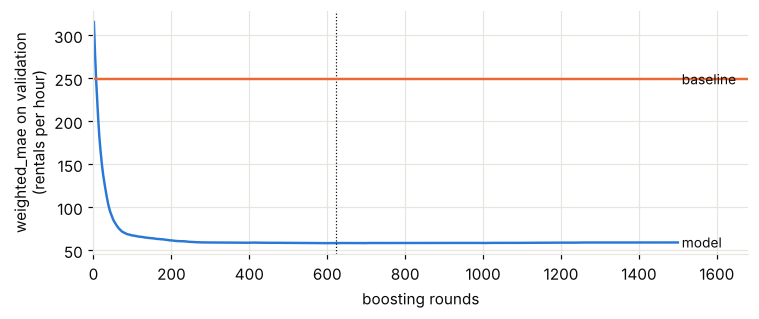

In [9]:
def make_model(n_iter):
    return HistGradientBoostingRegressor(
        loss="quantile", quantile=QUANTILE, learning_rate=LEARNING_RATE, max_iter=n_iter,
        max_leaf_nodes=MAX_LEAF_NODES, min_samples_leaf=MIN_SAMPLES_LEAF,
        early_stopping=False, random_state=SEED,
    )


probe = make_model(MAX_ITER).fit(X_all[is_train], y_all[is_train])
val_curve = [weighted_mae(y_val, np.clip(p, 0, None)) for p in probe.staged_predict(X_all[is_val])]
best_iter = int(np.argmin(val_curve)) + 1
print(f"Best number of rounds on validation: {best_iter} (weighted_mae = {min(val_curve):.2f})")
print(f"Baseline on validation:               weighted_mae = {weighted_mae(y_val, base_val):.2f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, MAX_ITER + 1), val_curve, color=C_MODEL)
ax.axvline(best_iter, color=C_INK, lw=0.8, ls=":")
ax.axhline(weighted_mae(y_val, base_val), color=C_BASE)
ax.text(MAX_ITER, weighted_mae(y_val, base_val), " baseline", color=C_INK, va="center", ha="left", fontsize=9)
ax.text(MAX_ITER, val_curve[-1], " model", color=C_INK, va="center", ha="left", fontsize=9)
ax.set(xlabel="boosting rounds", ylabel="weighted_mae on validation\n(rentals per hour)", xlim=(0, MAX_ITER * 1.12))
plt.tight_layout(); plt.show()

In [10]:
train_val = is_train | is_val
final_model = make_model(best_iter).fit(X_all[train_val], y_all[train_val])
print("Final model fitted on train + validation with", best_iter, "rounds")

Final model fitted on train + validation with 622 rounds


## 7. Evaluation on the test period (touched once)

In [11]:
pred_test = np.clip(final_model.predict(X_all[is_test]), 0, None)

results = pd.DataFrame({
    "baseline": score(y_test, base_test),
    "model": score(y_test, pred_test),
}).T
results["share of hours under-forecast"] = results.pop("under_share")
print(f"Test period: {y_test.index.min():%Y-%m-%d} to {y_test.index.max():%Y-%m-%d}, {len(y_test):,} hours")
results

Test period: 2012-10-01 to 2012-12-31, 2,208 hours


,weighted_mae,mae,share of hours under-forecast
baseline,134.979,79.938,0.661
model,52.782,40.406,0.396


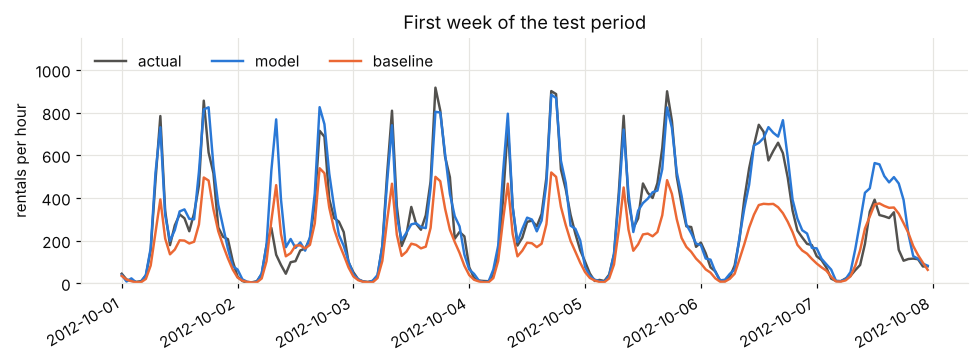

In [12]:
# one week of the test period: actual vs forecasts (direct labels, no dual axis)
week = y_test.index[: 24 * 7]
pos = np.arange(len(y_test))[: len(week)]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(week, y_test.iloc[pos], color=C_ACTUAL, label="actual")
ax.plot(week, pred_test[pos], color=C_MODEL, label="model")
ax.plot(week, base_test[pos], color=C_BASE, label="baseline")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set(ylabel="rentals per hour", title="First week of the test period", ylim=(0, 1150))
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

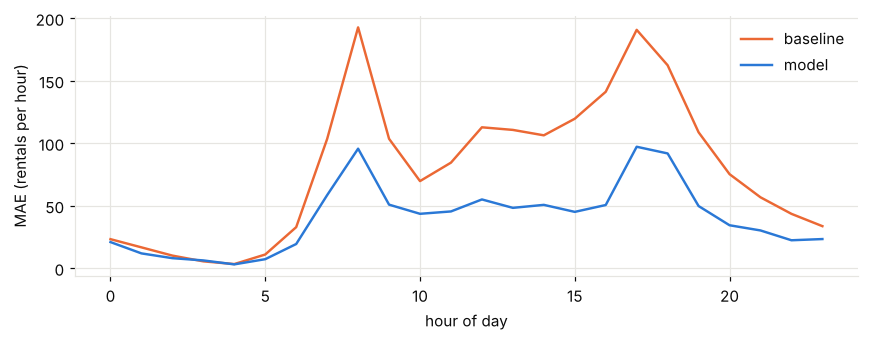

In [13]:
# where does the model help? error by hour of day
by_hr = pd.DataFrame({
    "baseline": pd.Series(np.abs(y_test.to_numpy() - base_test), index=y_test.index).groupby(y_test.index.hour).mean(),
    "model": pd.Series(np.abs(y_test.to_numpy() - pred_test), index=y_test.index).groupby(y_test.index.hour).mean(),
})
ax = by_hr.plot(figsize=(8, 3.2), color=[C_BASE, C_MODEL])
ax.set(xlabel="hour of day", ylabel="MAE (rentals per hour)")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 8. Release gate
Rules were fixed in the config cell before any result existed. The gate prints **PASS** only if every automated check passes.

| Check | How it is tested here |
| --- | --- |
| Beats baseline by the required margin | `weighted_mae_model <= (1 - REQUIRED_IMPROVEMENT) * weighted_mae_baseline` on the test period |
| Response time | p95 of 300 single-row predictions |
| Data quality | section 1 assertions |
| No leakage | section 3 tests |
| Cost per prediction | **not measurable in a notebook**: reported as NOT VERIFIED, to be checked in the deployed system |

In [14]:
# latency: single-row prediction, as a service would do it
rows = X_all[is_test].sample(300, random_state=SEED)
times = []
for i in range(len(rows)):
    t = time.perf_counter()
    final_model.predict(rows.iloc[[i]])
    times.append(time.perf_counter() - t)
p95_latency = float(np.percentile(times, 95))

wm_model = results.loc["model", "weighted_mae"]
wm_base = results.loc["baseline", "weighted_mae"]
ratio = wm_model / wm_base
threshold = (1 - REQUIRED_IMPROVEMENT) * wm_base

gate = pd.DataFrame([
    ["weighted_mae model <= " + f"{1 - REQUIRED_IMPROVEMENT:.2f} x baseline", f"{wm_model:.2f} vs limit {threshold:.2f} (ratio {ratio:.3f})", wm_model <= threshold],
    [f"p95 latency <= {MAX_P95_LATENCY_S} s", f"{p95_latency * 1000:.1f} ms", p95_latency <= MAX_P95_LATENCY_S],
    ["data quality checks passed", "section 1", DATA_QUALITY_OK],
    ["leakage tests passed", "section 3", LEAKAGE_OK],
], columns=["check", "result", "passed"])
gate["passed"] = gate["passed"].map({True: "PASS", False: "FAIL"})
gate.loc[len(gate)] = [f"cost <= EUR {MAX_COST_EUR} per prediction", "not measured here", "NOT VERIFIED"]
print(gate.to_string(index=False))

automated_ok = (gate["passed"].iloc[:4] == "PASS").all()
print()
if automated_ok:
    print("RELEASE GATE: PASS on all automated checks. Cost per prediction still has to be verified in the deployed system.")
else:
    print("RELEASE GATE: FAIL. Do not promote this model.")
    print("Failed:", ", ".join(gate.loc[gate["passed"] == "FAIL", "check"]))

                                check                              result       passed
weighted_mae model <= 0.85 x baseline 52.78 vs limit 114.73 (ratio 0.391)         PASS
                 p95 latency <= 1.0 s                              7.8 ms         PASS
           data quality checks passed                           section 1         PASS
                 leakage tests passed                           section 3         PASS
      cost <= EUR 0.01 per prediction                   not measured here NOT VERIFIED

RELEASE GATE: PASS on all automated checks. Cost per prediction still has to be verified in the deployed system.


## Things to break together
Each item is a one-line change in the config or a function. Predict the effect first, then run.

1. `LAG_MIN = 1`: how much does the latest hour help, and is that hour really available in production?
2. `USE_WEATHER = True`: accuracy goes up, but this is only valid with weather **forecasts**. What changes in the data contract?
3. `UNDER_WEIGHT = 1`: does the model change, and does the gate still use the right metric?
4. Move `TRAIN_END` and `VAL_END`: is the gate result stable, or does it depend on which season is the test period?
5. Shuffle the split on purpose: how much better does the score look, and why is it wrong?
6. Remove the missing-hour handling: which lag features silently shift?
7. Add `is_imputed` to the features: what does the leakage test say?
8. Drop `REQUIRED_IMPROVEMENT` to 0.05 after seeing the results: why is that not allowed?
9. Break the data on purpose (duplicate a row, rename a column): which section catches it?